# Regularization and Optimization on CIFAR-100

**Part 1** — Train a CNN on CIFAR-100 until it overfits, then compare **standard regularization (weight decay + augmentation)**, **Dropout**, and **Early Stopping** using iteration-level learning curves (loss & accuracy).

**Part 2** — Compare convergence speed of **SGD**, **AdaGrad**, **Adam**, and **RMSprop**, tracked with **MLflow**.


## 0. Setup — installs, imports, device, reproducibility

In [1]:
# Run once. If torch is already installed with CUDA support you can skip this cell.
# Make sure you install the CUDA build of torch matching your driver, e.g. (CUDA 12.1):
#   pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121
# Then the rest:
#   pip install mlflow matplotlib pandas numpy tqdm


In [2]:
%pip install torch torchvision torchaudio pandas matplotlib numpy

In [3]:
import os
import pickle
import time
import copy
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

# Mixed precision helps a lot on a 6GB card
USE_AMP = device.type == "cuda"


Device: cuda
GPU: Tesla T4
VRAM (GB): 15.64


## 1. Load the CIFAR-100 pickled dataset

In [ ]:
# ---- point this at your dataset folder ----
DATA_DIR = Path(r"/home/aditya-jaiswal/Coding Projects/College_Projects/AI-Enginnering (ML+DSA)/DL_LAB/LAB3")

TRAIN_FILE = DATA_DIR / "train"
TEST_FILE  = DATA_DIR / "test"
META_FILE  = DATA_DIR / "meta"

assert TRAIN_FILE.exists(), f"train file not found at {TRAIN_FILE}"
assert TEST_FILE.exists(),  f"test file not found at {TEST_FILE}"
assert META_FILE.exists(),  f"meta file not found at {META_FILE}"

def unpickle(path):
    """Robust unpickle: handles files that may contain a leading UTF-8 BOM
    or a replacement-char prefix, and falls back to latin1 decoding.
    Returns the unpickled object with original byte-string keys preserved.
    """
    with open(path, "rb") as f:
        data = f.read()

    # First try the normal load (encoding='bytes' preserves b'...' keys)
    try:
        return pickle.loads(data, encoding="bytes")
    except Exception:
        # If the file starts with a common UTF-8 BOM or replacement char,
        # strip it and retry.
        for prefix in (b"\xef\xbb\xbf", b"\xef\xbf\xbd"):
            if data.startswith(prefix):
                try:
                    return pickle.loads(data[len(prefix):], encoding="bytes")
                except Exception:
                    pass

        # As a last resort try latin1 (helps for some Python2-produced pickles)
        return pickle.loads(data, encoding="latin1")


train_dict = unpickle(TRAIN_FILE)
test_dict  = unpickle(TEST_FILE)
meta_dict  = unpickle(META_FILE)

fine_label_names = [x.decode("utf-8") for x in meta_dict[b"fine_label_names"]]
print("Num classes:", len(fine_label_names))
print("Train samples:", len(train_dict[b"fine_labels"]))
print("Test samples:", len(test_dict[b"fine_labels"]))


AssertionError: train file not found at /home/aditya-jaiswal/Coding Projects/College_Projects/AI-Enginnering (ML+DSA)/DL_LAB/LAB3/train

In [8]:
class CIFAR100Raw(Dataset):
    '''Reads directly from an unpickled CIFAR-100 dict (b'data', b'fine_labels').'''
    def __init__(self, data_dict, indices=None, transform=None):
        data = data_dict[b"data"]  # (N, 3072) uint8
        data = data.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)  # -> (N, 32, 32, 3) HWC
        labels = np.array(data_dict[b"fine_labels"], dtype=np.int64)

        if indices is not None:
            data = data[indices]
            labels = labels[indices]

        self.data = data
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.data[idx]  # HWC uint8
        label = int(self.labels[idx])
        if self.transform is not None:
            img = self.transform(img)
        return img, label


In [9]:
from torchvision import transforms

CIFAR100_MEAN = (0.5071, 0.4865, 0.4409)
CIFAR100_STD  = (0.2673, 0.2564, 0.2762)

train_transform_aug = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR100_MEAN, CIFAR100_STD),
])

train_transform_plain = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR100_MEAN, CIFAR100_STD),
])

eval_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR100_MEAN, CIFAR100_STD),
])

# held-out validation split carved out of the training set
N_TRAIN_TOTAL = len(train_dict[b"fine_labels"])
rng = np.random.RandomState(SEED)
perm = rng.permutation(N_TRAIN_TOTAL)
val_size = 5000
val_idx = perm[:val_size]
train_idx = perm[val_size:]

test_ds_full = CIFAR100Raw(test_dict, transform=eval_transform)
print("Val size:", len(val_idx), "| Train (full) size:", len(train_idx), "| Test size:", len(test_ds_full))


NameError: name 'train_dict' is not defined

## 2. Model — small VGG-style CNN with an optional Dropout switch

Kept compact (channels 64→128→256) so it trains comfortably on a 6GB GPU with batch size 128–256.

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=100, dropout_p=0.0, block_dropout_p=0.0):
        super().__init__()
        self.block_dropout_p = block_dropout_p

        def conv_block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
                nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            )

        self.block1 = conv_block(3, 64)
        self.block2 = conv_block(64, 128)
        self.block3 = conv_block(128, 256)
        self.pool = nn.MaxPool2d(2)
        self.spatial_drop = nn.Dropout2d(block_dropout_p) if block_dropout_p > 0 else nn.Identity()

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_p) if dropout_p > 0 else nn.Identity(),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.pool(self.block1(x)); x = self.spatial_drop(x)
        x = self.pool(self.block2(x)); x = self.spatial_drop(x)
        x = self.pool(self.block3(x)); x = self.spatial_drop(x)
        return self.classifier(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

_tmp = SmallCNN()
print("Trainable params:", f"{count_params(_tmp):,}")
del _tmp


Trainable params: 3,296,164


## 3. Generic training loop with iteration-level logging

Logs **train loss/accuracy every batch**, and **val loss/accuracy every epoch**, so both can be plotted on the same iteration x-axis. Supports optional early stopping.

In [ ]:
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                out = model(x)
                loss = criterion(out, y)
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total


def train_model(model, train_loader, val_loader, optimizer, criterion, epochs,
                 early_stopping=False, patience=5, log_every=1, run_label="run"):
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    history = {"iter": [], "train_loss": [], "train_acc": [],
               "val_iter": [], "val_loss": [], "val_acc": []}

    best_val_loss = float("inf")
    best_state = None
    epochs_no_improve = 0
    it = 0
    stopped_epoch = epochs

    for epoch in range(epochs):
        model.train()
        running_loss, running_correct, running_total = 0.0, 0, 0

        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                out = model(x)
                loss = criterion(out, y)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            batch_acc = (out.argmax(1) == y).float().mean().item()
            it += 1

            if it % log_every == 0:
                history["iter"].append(it)
                history["train_loss"].append(loss.item())
                history["train_acc"].append(batch_acc)

            running_loss += loss.item() * x.size(0)
            running_correct += (out.argmax(1) == y).sum().item()
            running_total += x.size(0)

        val_loss, val_acc = evaluate(model, val_loader, criterion)
        history["val_iter"].append(it)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        train_epoch_loss = running_loss / running_total
        train_epoch_acc = running_correct / running_total
        print(f"[{run_label}] epoch {epoch+1:>3}/{epochs} | "
              f"train_loss={train_epoch_loss:.4f} train_acc={train_epoch_acc:.4f} | "
              f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

        if early_stopping:
            if val_loss < best_val_loss - 1e-4:
                best_val_loss = val_loss
                best_state = copy.deepcopy(model.state_dict())
                epochs_no_improve = 0
            else:
                epochs_no_improve += 1
                if epochs_no_improve >= patience:
                    print(f"[{run_label}] Early stopping triggered at epoch {epoch+1} "
                          f"(no val improvement for {patience} epochs).")
                    stopped_epoch = epoch + 1
                    break

    if early_stopping and best_state is not None:
        model.load_state_dict(best_state)

    history["stopped_epoch"] = stopped_epoch
    return history


## 4. Part 1 — Runs

Four runs, same architecture family, isolating one factor at a time:

1. **Baseline (overfit demo)** — small training subset, no augmentation, no weight decay, no dropout, trained long enough to clearly overfit.
2. **Standard regularization** — full training set, data augmentation + weight decay (L2).
3. **Dropout** — full training set, dropout in the classifier head + spatial dropout after each block, no weight decay.
4. **Early Stopping** — same as baseline setup (no aug/weight decay/dropout) but training halts once validation loss stops improving.

Batch size and epoch counts are tuned to be light enough for a 6GB GPU; increase `EPOCHS_*` if you have time/VRAM to spare.

In [ ]:
BATCH_SIZE = 128
NUM_WORKERS = 0  # keep modest on Windows to avoid worker startup overhead

def make_loader(dataset, indices, transform, shuffle, batch_size=BATCH_SIZE):
    ds = CIFAR100Raw(train_dict, indices=indices, transform=transform)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                       num_workers=NUM_WORKERS, pin_memory=True, drop_last=False)

val_loader = make_loader(train_dict, val_idx, eval_transform, shuffle=False)
test_loader = DataLoader(test_ds_full, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)


In [ ]:
# ---- Run 1: Baseline overfit demo ----
# Small subset + no regularization + enough epochs to clearly overfit.
OVERFIT_SUBSET_SIZE = 4000

overfit_idx = train_idx[:OVERFIT_SUBSET_SIZE]
overfit_loader = make_loader(train_dict, overfit_idx, train_transform_plain, shuffle=True)

EPOCHS_BASELINE = 40

model_baseline = SmallCNN(num_classes=100, dropout_p=0.0, block_dropout_p=0.0).to(device)
opt_baseline = torch.optim.Adam(model_baseline.parameters(), lr=1e-3, weight_decay=0.0)
criterion = nn.CrossEntropyLoss()

history_baseline = train_model(
    model_baseline, overfit_loader, val_loader, opt_baseline, criterion,
    epochs=EPOCHS_BASELINE, early_stopping=False, log_every=1, run_label="baseline-overfit",
)


C:\Users\aman kumar jha\AppData\Local\Temp\ipykernel_16360\3827696537.py:18: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
d:\Anaconda Folder\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[baseline-overfit] epoch   1/40 | train_loss=4.5874 train_acc=0.0310 | val_loss=4.2523 val_acc=0.0470
[baseline-overfit] epoch   2/40 | train_loss=4.1154 train_acc=0.0685 | val_loss=4.0984 val_acc=0.0612
[baseline-overfit] epoch   3/40 | train_loss=3.9076 train_acc=0.0892 | val_loss=4.2753 val_acc=0.0704
[baseline-overfit] epoch   4/40 | train_loss=3.7538 train_acc=0.1153 | val_loss=3.9007 val_acc=0.0958


In [ ]:
# ---- Run 2: Standard regularization (weight decay + data augmentation) ----
EPOCHS_REG = 25
full_train_loader_aug = make_loader(train_dict, train_idx, train_transform_aug, shuffle=True)

model_reg = SmallCNN(num_classes=100, dropout_p=0.0, block_dropout_p=0.0).to(device)
opt_reg = torch.optim.Adam(model_reg.parameters(), lr=1e-3, weight_decay=5e-4)

history_reg = train_model(
    model_reg, full_train_loader_aug, val_loader, opt_reg, criterion,
    epochs=EPOCHS_REG, early_stopping=False, log_every=1, run_label="standard-reg",
)


C:\Users\AAYUSH PRAVEEN\AppData\Local\Temp\ipykernel_6392\3827696537.py:18: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


[standard-reg] epoch   1/25 | train_loss=3.8925 train_acc=0.0979 | val_loss=3.4615 val_acc=0.1612
[standard-reg] epoch   2/25 | train_loss=3.1515 train_acc=0.2161 | val_loss=2.9996 val_acc=0.2490
[standard-reg] epoch   3/25 | train_loss=2.6280 train_acc=0.3148 | val_loss=2.5931 val_acc=0.3204
[standard-reg] epoch   4/25 | train_loss=2.3214 train_acc=0.3776 | val_loss=2.2310 val_acc=0.4002
[standard-reg] epoch   5/25 | train_loss=2.1113 train_acc=0.4280 | val_loss=2.1683 val_acc=0.4138
[standard-reg] epoch   6/25 | train_loss=1.9446 train_acc=0.4633 | val_loss=1.9500 val_acc=0.4674
[standard-reg] epoch   7/25 | train_loss=1.8139 train_acc=0.4962 | val_loss=1.8873 val_acc=0.4820
[standard-reg] epoch   8/25 | train_loss=1.7094 train_acc=0.5201 | val_loss=1.8145 val_acc=0.4984
[standard-reg] epoch   9/25 | train_loss=1.6191 train_acc=0.5450 | val_loss=2.2209 val_acc=0.4370
[standard-reg] epoch  10/25 | train_loss=1.5395 train_acc=0.5616 | val_loss=1.6899 val_acc=0.5362
[standard-reg] epoch

In [ ]:
# ---- Run 3: Dropout ----
EPOCHS_DROPOUT = 25
full_train_loader_plain = make_loader(train_dict, train_idx, train_transform_plain, shuffle=True)

model_dropout = SmallCNN(num_classes=100, dropout_p=0.5, block_dropout_p=0.2).to(device)
opt_dropout = torch.optim.Adam(model_dropout.parameters(), lr=1e-3, weight_decay=0.0)

history_dropout = train_model(
    model_dropout, full_train_loader_plain, val_loader, opt_dropout, criterion,
    epochs=EPOCHS_DROPOUT, early_stopping=False, log_every=1, run_label="dropout",
)


C:\Users\AAYUSH PRAVEEN\AppData\Local\Temp\ipykernel_6392\3827696537.py:18: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


[dropout] epoch   1/25 | train_loss=4.2534 train_acc=0.0460 | val_loss=3.8369 val_acc=0.0926
[dropout] epoch   2/25 | train_loss=3.9195 train_acc=0.0846 | val_loss=3.5543 val_acc=0.1338
[dropout] epoch   3/25 | train_loss=3.7264 train_acc=0.1136 | val_loss=3.3478 val_acc=0.1854
[dropout] epoch   4/25 | train_loss=3.5678 train_acc=0.1388 | val_loss=3.1531 val_acc=0.2080
[dropout] epoch   5/25 | train_loss=3.4339 train_acc=0.1616 | val_loss=3.0060 val_acc=0.2504
[dropout] epoch   6/25 | train_loss=3.3259 train_acc=0.1780 | val_loss=2.8696 val_acc=0.2790
[dropout] epoch   7/25 | train_loss=3.2128 train_acc=0.1986 | val_loss=2.7741 val_acc=0.3012
[dropout] epoch   8/25 | train_loss=3.1000 train_acc=0.2179 | val_loss=2.6753 val_acc=0.3206
[dropout] epoch   9/25 | train_loss=3.0076 train_acc=0.2374 | val_loss=2.5120 val_acc=0.3488
[dropout] epoch  10/25 | train_loss=2.8984 train_acc=0.2536 | val_loss=2.4289 val_acc=0.3680
[dropout] epoch  11/25 | train_loss=2.8100 train_acc=0.2719 | val_loss

In [ ]:
# ---- Run 4: Early Stopping ----
EPOCHS_ES_MAX = 40
PATIENCE = 5

model_es = SmallCNN(num_classes=100, dropout_p=0.0, block_dropout_p=0.0).to(device)
opt_es = torch.optim.Adam(model_es.parameters(), lr=1e-3, weight_decay=0.0)

history_es = train_model(
    model_es, full_train_loader_plain, val_loader, opt_es, criterion,
    epochs=EPOCHS_ES_MAX, early_stopping=True, patience=PATIENCE, log_every=1, run_label="early-stopping",
)


C:\Users\AAYUSH PRAVEEN\AppData\Local\Temp\ipykernel_6392\3827696537.py:18: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


[early-stopping] epoch   1/40 | train_loss=3.6881 train_acc=0.1361 | val_loss=3.3169 val_acc=0.2100
[early-stopping] epoch   2/40 | train_loss=2.7800 train_acc=0.2916 | val_loss=2.5717 val_acc=0.3424
[early-stopping] epoch   3/40 | train_loss=2.2177 train_acc=0.4057 | val_loss=2.1834 val_acc=0.4242
[early-stopping] epoch   4/40 | train_loss=1.8697 train_acc=0.4864 | val_loss=2.0631 val_acc=0.4476
[early-stopping] epoch   5/40 | train_loss=1.6060 train_acc=0.5470 | val_loss=1.9578 val_acc=0.4806
[early-stopping] epoch   6/40 | train_loss=1.3839 train_acc=0.6043 | val_loss=1.8511 val_acc=0.5062
[early-stopping] epoch   7/40 | train_loss=1.1779 train_acc=0.6546 | val_loss=2.0232 val_acc=0.4822
[early-stopping] epoch   8/40 | train_loss=0.9780 train_acc=0.7063 | val_loss=1.8653 val_acc=0.5260
[early-stopping] epoch   9/40 | train_loss=0.7870 train_acc=0.7599 | val_loss=1.9781 val_acc=0.5252
[early-stopping] epoch  10/40 | train_loss=0.6086 train_acc=0.8130 | val_loss=2.0382 val_acc=0.5284


## 5. Learning curves — comparing the four runs

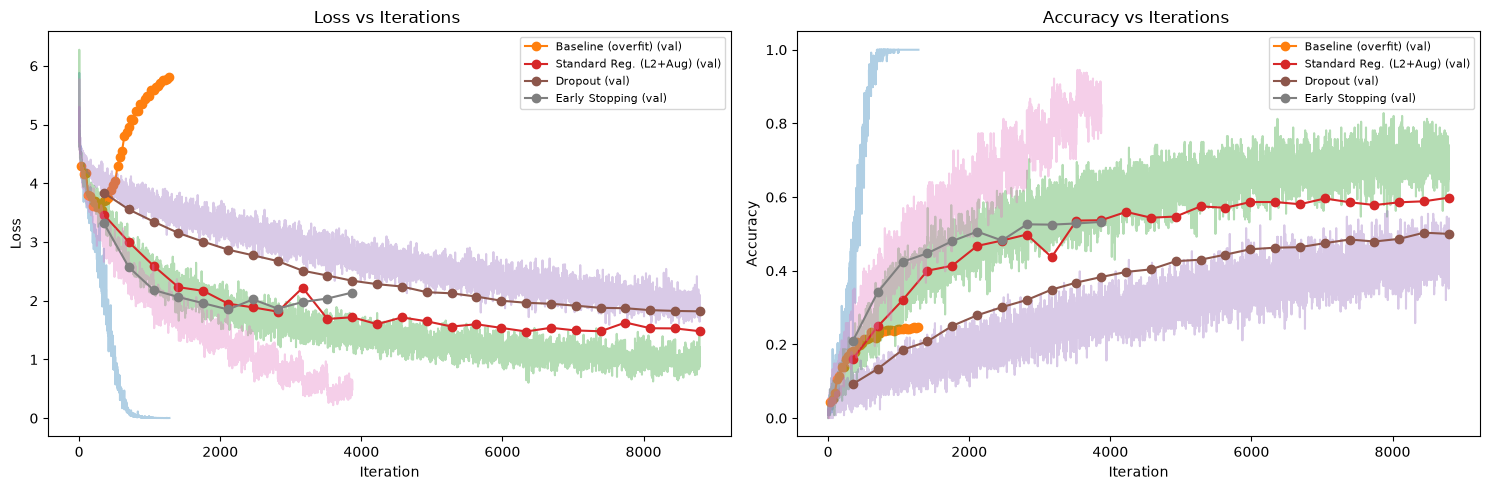

In [ ]:
def plot_comparison(histories, labels, title_suffix=""):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    for h, label in zip(histories, labels):
        axes[0].plot(h["iter"], h["train_loss"], alpha=0.35)
        axes[0].plot(h["val_iter"], h["val_loss"], marker="o", label=f"{label} (val)")

        axes[1].plot(h["iter"], h["train_acc"], alpha=0.35)
        axes[1].plot(h["val_iter"], h["val_acc"], marker="o", label=f"{label} (val)")

    axes[0].set_title(f"Loss vs Iterations {title_suffix}")
    axes[0].set_xlabel("Iteration"); axes[0].set_ylabel("Loss")
    axes[0].legend(fontsize=8)

    axes[1].set_title(f"Accuracy vs Iterations {title_suffix}")
    axes[1].set_xlabel("Iteration"); axes[1].set_ylabel("Accuracy")
    axes[1].legend(fontsize=8)

    plt.tight_layout()
    plt.show()

histories = [history_baseline, history_reg, history_dropout, history_es]
labels = ["Baseline (overfit)", "Standard Reg. (L2+Aug)", "Dropout", "Early Stopping"]

plot_comparison(histories, labels)


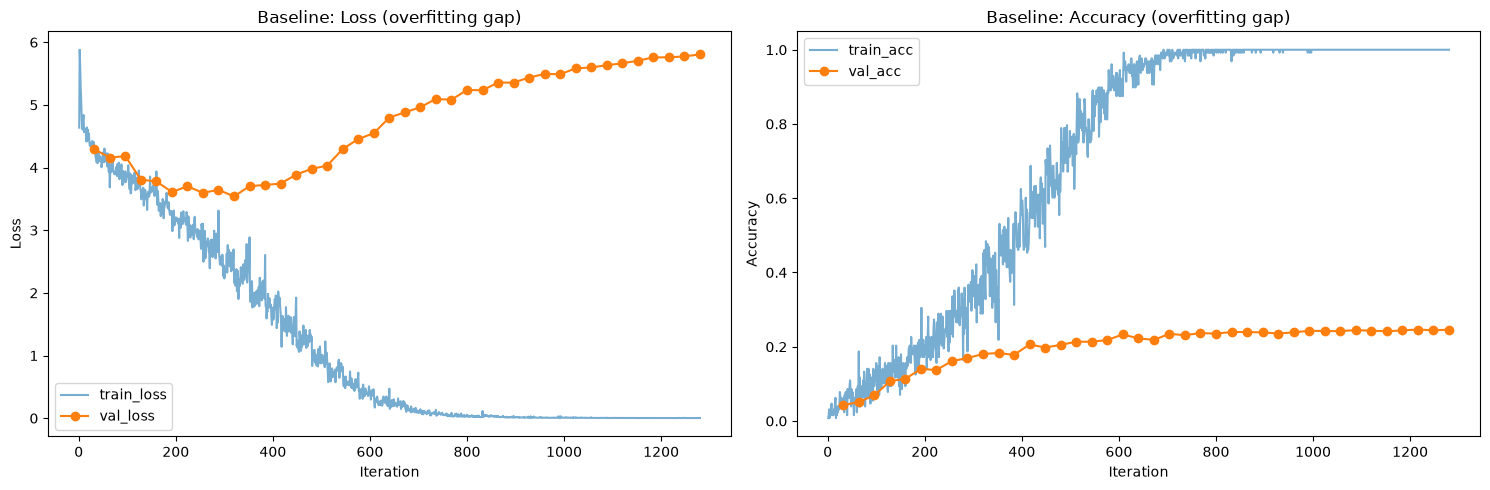

In [ ]:
# Baseline alone, faded train curve + val curve, makes the overfitting gap explicit
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(history_baseline["iter"], history_baseline["train_loss"], label="train_loss", alpha=0.6)
axes[0].plot(history_baseline["val_iter"], history_baseline["val_loss"], label="val_loss", marker="o")
axes[0].set_title("Baseline: Loss (overfitting gap)"); axes[0].set_xlabel("Iteration"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].plot(history_baseline["iter"], history_baseline["train_acc"], label="train_acc", alpha=0.6)
axes[1].plot(history_baseline["val_iter"], history_baseline["val_acc"], label="val_acc", marker="o")
axes[1].set_title("Baseline: Accuracy (overfitting gap)"); axes[1].set_xlabel("Iteration"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()


In [ ]:
# Final test-set numbers for each regularized model (baseline excluded on purpose: trained on a tiny subset)
for name, m in [("Standard Reg.", model_reg), ("Dropout", model_dropout), ("Early Stopping", model_es)]:
    test_loss, test_acc = evaluate(m, test_loader, criterion)
    print(f"{name:16s} | test_loss={test_loss:.4f} test_acc={test_acc:.4f}")


Standard Reg.    | test_loss=1.5225 test_acc=0.5918
Dropout          | test_loss=1.8337 test_acc=0.4999
Early Stopping   | test_loss=1.8468 test_acc=0.5066


## 6. Part 2 — Optimizer convergence speed with MLflow

We point MLflow at a **local, non-OneDrive folder** for the tracking store to avoid file-locking issues (see troubleshooting cell below). All four optimizers start from the **same initial weights** for a fair comparison, and we log **per-iteration** train loss/accuracy so early convergence speed is visible.

In [ ]:
import mlflow

# IMPORTANT: keep this folder OUTSIDE OneDrive-synced paths.
# If this notebook itself lives under OneDrive, override MLFLOW_DIR below with
# something like: Path(r"C:\mlflow_data\cifar100_mlruns")
MLFLOW_DIR = Path.cwd() / "mlruns_cifar100"
MLFLOW_DIR.mkdir(parents=True, exist_ok=True)

# Recent MLflow versions disable the plain filesystem backend ("file:...") by default -
# it's in maintenance mode and raises MlflowException unless you opt in. We use a local
# SQLite database instead (still just a single local file, no server required, and this
# is MLflow's currently-recommended local backend).
db_path = (MLFLOW_DIR / "mlflow.db").resolve()
mlflow.set_tracking_uri(f"sqlite:///{db_path}")
mlflow.set_experiment("CIFAR100_Optimizer_Comparison")

print("MLflow tracking URI:", mlflow.get_tracking_uri())


2026/08/31 18:36:12 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/08/31 18:36:13 INFO mlflow.store.db.utils: Updating database tables
2026/08/31 18:36:14 INFO mlflow.tracking.fluent: Experiment with name 'CIFAR100_Optimizer_Comparison' does not exist. Creating a new experiment.


MLflow tracking URI: sqlite:///C:\Users\AAYUSH PRAVEEN\OneDrive\Desktop\CIFAR-100\mlruns_cifar100\mlflow.db


In [ ]:
def get_optimizer(name, params, lr):
    name = name.lower()
    if name == "sgd":
        return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if name == "adagrad":
        return torch.optim.Adagrad(params, lr=lr)
    if name == "adam":
        return torch.optim.Adam(params, lr=lr)
    if name == "rmsprop":
        return torch.optim.RMSprop(params, lr=lr)
    raise ValueError(f"Unknown optimizer: {name}")

# Common learning rate kept the same across optimizers for a like-for-like comparison.
# (In practice SGD often wants a higher LR than Adam/RMSprop/AdaGrad - feel free to tune per-optimizer.)
OPT_LR = 1e-3
OPT_EPOCHS = 6
OPT_LOG_EVERY = 1  # log every batch so the early-iteration convergence speed is visible

# Freeze a shared initialization so every optimizer starts from the same point
init_model = SmallCNN(num_classes=100, dropout_p=0.0, block_dropout_p=0.0).to(device)
INIT_STATE = copy.deepcopy(init_model.state_dict())
del init_model


In [ ]:
def train_with_mlflow(optimizer_name, train_loader, val_loader, epochs, lr, log_every=1):
    model = SmallCNN(num_classes=100, dropout_p=0.0, block_dropout_p=0.0).to(device)
    model.load_state_dict(INIT_STATE)  # identical starting point for every optimizer
    optimizer = get_optimizer(optimizer_name, model.parameters(), lr)
    criterion = nn.CrossEntropyLoss()
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    local_history = {"iter": [], "train_loss": [], "train_acc": [],
                      "val_iter": [], "val_loss": [], "val_acc": []}

    with mlflow.start_run(run_name=optimizer_name):
        mlflow.log_params({
            "optimizer": optimizer_name, "lr": lr, "epochs": epochs,
            "batch_size": BATCH_SIZE, "architecture": "SmallCNN",
        })

        it = 0
        for epoch in range(epochs):
            model.train()
            for x, y in train_loader:
                x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)

                with torch.autocast(device_type="cuda", enabled=USE_AMP):
                    out = model(x)
                    loss = criterion(out, y)

                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

                batch_acc = (out.argmax(1) == y).float().mean().item()
                it += 1

                if it % log_every == 0:
                    local_history["iter"].append(it)
                    local_history["train_loss"].append(loss.item())
                    local_history["train_acc"].append(batch_acc)
                    mlflow.log_metric("train_loss", loss.item(), step=it)
                    mlflow.log_metric("train_acc", batch_acc, step=it)

            val_loss, val_acc = evaluate(model, val_loader, criterion)
            local_history["val_iter"].append(it)
            local_history["val_loss"].append(val_loss)
            local_history["val_acc"].append(val_acc)
            mlflow.log_metric("val_loss", val_loss, step=it)
            mlflow.log_metric("val_acc", val_acc, step=it)
            print(f"[{optimizer_name}] epoch {epoch+1}/{epochs} val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

    return local_history


In [ ]:
optimizer_names = ["SGD", "AdaGrad", "Adam", "RMSprop"]
optimizer_histories = {}

for name in optimizer_names:
    print(f"\n=== Training with {name} ===")
    optimizer_histories[name] = train_with_mlflow(
        name, full_train_loader_plain, val_loader,
        epochs=OPT_EPOCHS, lr=OPT_LR, log_every=OPT_LOG_EVERY,
    )



=== Training with SGD ===


C:\Users\AAYUSH PRAVEEN\AppData\Local\Temp\ipykernel_6392\296471730.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


[SGD] epoch 1/6 val_loss=3.4634 val_acc=0.1910
[SGD] epoch 2/6 val_loss=2.9815 val_acc=0.2642
[SGD] epoch 3/6 val_loss=2.6497 val_acc=0.3350
[SGD] epoch 4/6 val_loss=2.4686 val_acc=0.3682
[SGD] epoch 5/6 val_loss=2.3349 val_acc=0.3956
[SGD] epoch 6/6 val_loss=2.1458 val_acc=0.4338

=== Training with AdaGrad ===
[AdaGrad] epoch 1/6 val_loss=2.9800 val_acc=0.2706
[AdaGrad] epoch 2/6 val_loss=2.6397 val_acc=0.3286
[AdaGrad] epoch 3/6 val_loss=2.4919 val_acc=0.3708
[AdaGrad] epoch 4/6 val_loss=2.3459 val_acc=0.3982
[AdaGrad] epoch 5/6 val_loss=2.2679 val_acc=0.4136
[AdaGrad] epoch 6/6 val_loss=2.1847 val_acc=0.4284

=== Training with Adam ===
[Adam] epoch 1/6 val_loss=3.2849 val_acc=0.1958
[Adam] epoch 2/6 val_loss=2.5552 val_acc=0.3374
[Adam] epoch 3/6 val_loss=2.2977 val_acc=0.3860
[Adam] epoch 4/6 val_loss=2.0673 val_acc=0.4378
[Adam] epoch 5/6 val_loss=1.9113 val_acc=0.4846
[Adam] epoch 6/6 val_loss=1.8142 val_acc=0.5118

=== Training with RMSprop ===
[RMSprop] epoch 1/6 val_loss=3.888

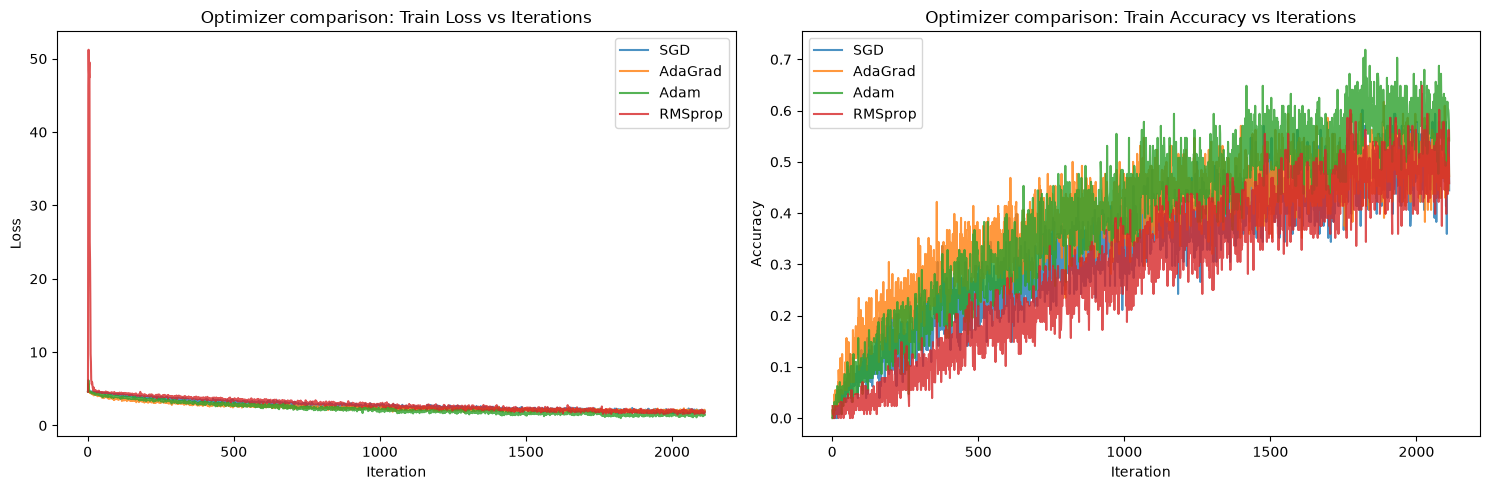

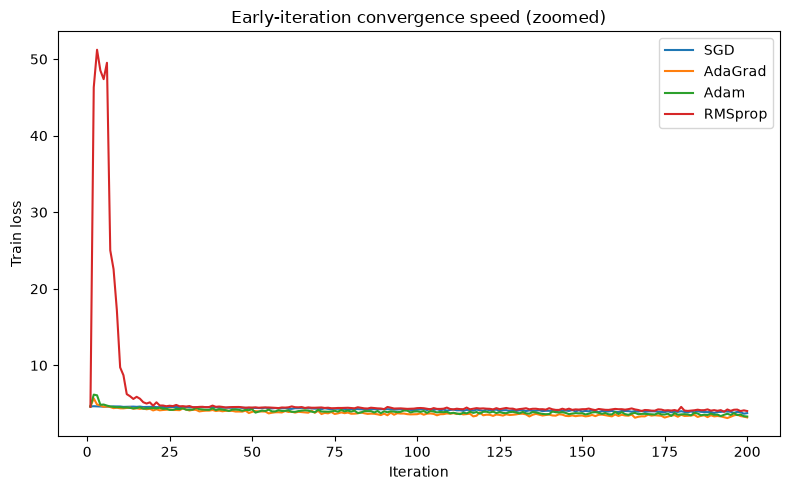

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name in optimizer_names:
    h = optimizer_histories[name]
    axes[0].plot(h["iter"], h["train_loss"], label=name, alpha=0.8)
    axes[1].plot(h["iter"], h["train_acc"], label=name, alpha=0.8)

axes[0].set_title("Optimizer comparison: Train Loss vs Iterations")
axes[0].set_xlabel("Iteration"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].set_title("Optimizer comparison: Train Accuracy vs Iterations")
axes[1].set_xlabel("Iteration"); axes[1].set_ylabel("Accuracy"); axes[1].legend()

plt.tight_layout(); plt.show()

# Zoom into the first ~200 iterations to compare how quickly each optimizer "starts learning"
fig, ax = plt.subplots(figsize=(8, 5))
ZOOM = 200
for name in optimizer_names:
    h = optimizer_histories[name]
    n = min(ZOOM, len(h["iter"]))
    ax.plot(h["iter"][:n], h["train_loss"][:n], label=name)
ax.set_title("Early-iteration convergence speed (zoomed)")
ax.set_xlabel("Iteration"); ax.set_ylabel("Train loss"); ax.legend()
plt.tight_layout(); plt.show()


### View results in the MLflow UI

From a terminal in this notebook's working directory (**not** inside a OneDrive-synced folder), run:

```bash
mlflow ui --backend-store-uri "sqlite:///mlruns_cifar100/mlflow.db" --port 5000
```

then open `http://127.0.0.1:5000`.

### MLflow backend troubleshooting (common issues)

- **`MlflowException: The filesystem tracking backend ... is in maintenance mode`** — recent MLflow versions disabled the plain `file:...` backend by default. Either (a) use a SQLite backend instead, as this notebook does (`sqlite:///.../mlflow.db`) — this is the recommended fix, and SQLite is still just one local file, no server needed — or (b) if you specifically want the old folder-of-files layout, opt back in with `os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"` *before* calling `mlflow.set_tracking_uri()`.
- **`OSError` / "database is locked" / weird sync errors** — almost always caused by pointing the tracking folder at a **OneDrive/Dropbox/Google Drive–synced folder**. OneDrive briefly locks files while syncing, which corrupts MLflow's local store (file-based or SQLite) mid-write. Fix: point `MLFLOW_DIR` at a plain local path (e.g. `C:\mlflow_data\...`) outside any synced folder, as done above.
- **"Port already in use" when running `mlflow ui`** — another `mlflow ui` process is already running; use `--port 5001` (or another free port), or kill the existing process.
- **Corrupted store after a kernel crash** — delete `mlruns_cifar100/mlflow.db` (or the specific run folder if using the file backend) and start fresh; you'll lose old run history but not your code.
- **`ModuleNotFoundError: No module named 'mlflow'`** — `pip install mlflow` in the same environment/kernel this notebook is using.
- **Very long Windows paths under OneDrive causing failures** — keep `MLFLOW_DIR` short and close to the drive root (e.g. `C:\mlflow_data\...`) rather than nested deep under `OneDrive\Desktop\...`.


## 7. Summary

- **Part 1**: the baseline model (trained on a small subset with no regularization) shows a widening train/val gap — classic overfitting. Standard regularization (L2 weight decay + augmentation) and Dropout both narrow that gap; Early Stopping halts training near the point where validation loss stops improving, avoiding wasted epochs of overfitting.
- **Part 2**: plotting train loss/accuracy per iteration for SGD, AdaGrad, Adam, and RMSprop (all from identical initial weights) makes it easy to see which optimizers reduce loss fastest in the first few dozen/hundred iterations versus which take longer to "get going". All runs are logged to MLflow for later inspection/comparison in the UI.
